In [26]:

import os
import sys
import math
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

print("MiniMind AI Project")
print("===================")
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")


MiniMind AI Project
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
NumPy: 2.4.6
Device: cuda
GPU: Tesla T4


In [27]:

educational_text = """
Artificial intelligence is a branch of computer science.
Artificial intelligence enables machines to perform intelligent tasks.
Machine learning is a part of artificial intelligence.
Machine learning allows computers to learn from data.
Deep learning uses artificial neural networks.
Neural networks are inspired by the human brain.
Python is a popular programming language.
Python is widely used in artificial intelligence.
Data science involves collecting and analyzing data.
A dataset contains a collection of information.
A computer processes data using instructions.
Algorithms are step by step procedures for solving problems.
A neural network contains layers of connected neurons.
The input layer receives information.
The hidden layers process information.
The output layer produces predictions.
A transformer is a deep learning architecture.
Transformers use an attention mechanism.
Self attention helps a model understand relationships between words.
Language models learn patterns from text.
A language model predicts the next token.
Tokens represent pieces of text.
Training improves the model parameters.
A loss function measures prediction errors.
An optimizer updates the model parameters.
PyTorch is a deep learning framework.
Google Colab provides a cloud notebook environment.
A GPU accelerates mathematical computations.
Natural language processing helps computers understand human language.
Education helps students develop knowledge and skills.
Students can use technology to improve learning.
Programming teaches logical problem solving.
"""

print("Dataset created successfully!")
print("Total characters:", len(educational_text))
print("Dataset preview:")
print(educational_text[:300])


Dataset created successfully!
Total characters: 1561
Dataset preview:

Artificial intelligence is a branch of computer science.
Artificial intelligence enables machines to perform intelligent tasks.
Machine learning is a part of artificial intelligence.
Machine learning allows computers to learn from data.
Deep learning uses artificial neural networks.
Neural networks


In [28]:

with open("minimind_dataset.txt", "w", encoding="utf-8") as file:
    file.write(educational_text)

print("Dataset saved successfully!")


Dataset saved successfully!


In [29]:

# Create vocabulary

chars = sorted(list(set(educational_text)))

vocab_size = len(chars)

# Character to integer mapping
stoi = {ch: i for i, ch in enumerate(chars)}

# Integer to character mapping
itos = {i: ch for i, ch in enumerate(chars)}

# Encoder function
def encode(text):
    return [stoi[ch] for ch in text if ch in stoi]

# Decoder function
def decode(tokens):
    return ''.join([itos[int(i)] for i in tokens])

print("Vocabulary Size:", vocab_size)
print("Sample Encoding:", encode("Artificial"))
print("Sample Decoding:", decode(encode("Artificial")))


Vocabulary Size: 39
Sample Encoding: [3, 30, 32, 23, 20, 23, 17, 23, 15, 25]
Sample Decoding: Artificial


In [30]:

data = torch.tensor(encode(educational_text), dtype=torch.long)

print("Total Tokens:", len(data))
print("Data Shape:", data.shape)
print("First 20 Tokens:", data[:20].tolist())


Total Tokens: 1561
Data Shape: torch.Size([1561])
First 20 Tokens: [0, 3, 30, 32, 23, 20, 23, 17, 23, 15, 25, 1, 23, 27, 32, 19, 25, 25, 23, 21]


In [31]:

split_index = int(0.9 * len(data))

train_data = data[:split_index]
val_data = data[split_index:]

print("Training Tokens:", len(train_data))
print("Validation Tokens:", len(val_data))


Training Tokens: 1404
Validation Tokens: 157


In [32]:

batch_size = 32
block_size = 64

def get_batch(split):
    source = train_data if split == "train" else val_data

    ix = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        source[i:i + block_size] for i in ix
    ])

    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in ix
    ])

    return x.to(device), y.to(device)

xb, yb = get_batch("train")

print("Input Shape:", xb.shape)
print("Target Shape:", yb.shape)


Input Shape: torch.Size([32, 64])
Target Shape: torch.Size([32, 64])


In [33]:

# MiniMind AI configuration

batch_size = 32
block_size = 64

max_iters = 1000
learning_rate = 3e-4

n_embd = 128
n_head = 4
n_layer = 4

dropout = 0.1

print("Model Configuration")
print("-------------------")
print("Embedding Size:", n_embd)
print("Attention Heads:", n_head)
print("Transformer Layers:", n_layer)
print("Training Iterations:", max_iters)


Model Configuration
-------------------
Embedding Size: 128
Attention Heads: 4
Transformer Layers: 4
Training Iterations: 1000


In [ ]:

class Head(nn.Module):

    def __init__(self, head_size):
        super().__init__()

        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        self.register_buffer(
            "tril",
            torch.tril(torch.ones(block_size, block_size))
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        B, T, C = x.shape

        k = self.key(x)
        q = self.query(x)

        weights = q @ k.transpose(-2, -1)
        weights = weights * (k.shape[-1] ** -0.5)

        weights = weights.masked_fill(
            self.tril[:T, :T] == 0,
            float("-inf")
        )

        weights = F.softmax(weights, dim=-1)
        weights = self.dropout(weights)

        v = self.value(x)

        output = weights @ v

        return output


In [34]:

class FeedForward(nn.Module):

    def __init__(self, n_embd):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(n_embd, 4 * n_embd),

            nn.ReLU(),

            nn.Linear(4 * n_embd, n_embd),

            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.network(x)


In [35]:

class Block(nn.Module):

    def __init__(self, n_embd, n_head):
        super().__init__()

        head_size = n_embd // n_head

        self.attention = MultiHeadAttention(
            n_head,
            head_size
        )

        self.feed_forward = FeedForward(n_embd)

        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):

        x = x + self.attention(self.ln1(x))

        x = x + self.feed_forward(self.ln2(x))

        return x


In [36]:

class MiniMindAI(nn.Module):

    def __init__(self):
        super().__init__()

        self.token_embedding = nn.Embedding(
            vocab_size,
            n_embd
        )

        self.position_embedding = nn.Embedding(
            block_size,
            n_embd
        )

        self.blocks = nn.Sequential(*[
            Block(n_embd, n_head)
            for _ in range(n_layer)
        ])

        self.final_norm = nn.LayerNorm(n_embd)

        self.output_layer = nn.Linear(
            n_embd,
            vocab_size
        )

    def forward(self, idx, targets=None):

        B, T = idx.shape

        token_emb = self.token_embedding(idx)

        positions = torch.arange(T, device=idx.device)

        position_emb = self.position_embedding(positions)

        x = token_emb + position_emb

        x = self.blocks(x)

        x = self.final_norm(x)

        logits = self.output_layer(x)

        loss = None

        if targets is not None:

            B, T, C = logits.shape

            logits = logits.view(B * T, C)

            targets = targets.view(B * T)

            loss = F.cross_entropy(logits, targets)

        return logits.view(B, T, vocab_size), loss

    def generate(self, idx, max_new_tokens=100):

        for _ in range(max_new_tokens):

            idx_cond = idx[:, -block_size:]

            logits, loss = self(idx_cond)

            logits = logits[:, -1, :]

            probabilities = F.softmax(logits, dim=-1)

            idx_next = torch.multinomial(
                probabilities,
                num_samples=1
            )

            idx = torch.cat((idx, idx_next), dim=1)

        return idx


In [38]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(num_heads * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

In [45]:

# Cell 9: Self Attention Head

class Head(nn.Module):

    def __init__(self, head_size):
        super().__init__()

        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        self.register_buffer(
            "tril",
            torch.tril(torch.ones(block_size, block_size))
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        B, T, C = x.shape

        k = self.key(x)
        q = self.query(x)

        weights = q @ k.transpose(-2, -1)
        weights = weights * (k.shape[-1] ** -0.5)

        weights = weights.masked_fill(
            self.tril[:T, :T] == 0,
            float("-inf")
        )

        weights = F.softmax(weights, dim=-1)
        weights = self.dropout(weights)

        v = self.value(x)

        output = weights @ v

        return output

print("Self Attention Head defined successfully!")


Self Attention Head defined successfully!


In [46]:

model = MiniMindAI().to(device)

print("MiniMind AI Transformer Created!")

print("Total Parameters:",
      sum(p.numel() for p in model.parameters()))

xb, yb = get_batch("train")

logits, loss = model(xb, yb)

print("Output Shape:", logits.shape)
print("Initial Loss:", loss.item())


MiniMind AI Transformer Created!
Total Parameters: 810023
Output Shape: torch.Size([32, 64, 39])
Initial Loss: 3.80094575881958


In [47]:

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)

print("AdamW optimizer initialized!")


AdamW optimizer initialized!


In [48]:

@torch.no_grad()
def estimate_loss():

    model.eval()

    results = {}

    for split in ["train", "val"]:

        losses = []

        for _ in range(20):

            xb, yb = get_batch(split)

            logits, loss = model(xb, yb)

            losses.append(loss.item())

        results[split] = np.mean(losses)

    model.train()

    return results


In [49]:
model = MiniMindAI().to(device)
print("MiniMindAI model instantiated!")

MiniMindAI model instantiated!


In [50]:

train_losses = []
val_losses = []

model.train()

for iteration in range(max_iters):

    if iteration % 100 == 0:

        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])

        print(
            f"Step {iteration}: "
            f"Train Loss {losses['train']:.4f}, "
            f"Validation Loss {losses['val']:.4f}"
        )

    xb, yb = get_batch("train")

    logits, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)

    loss.backward()

    optimizer.step()

print("Training Completed Successfully!")


Step 0: Train Loss 3.8175, Validation Loss 3.8565
Step 100: Train Loss 3.8180, Validation Loss 3.8552
Step 200: Train Loss 3.8213, Validation Loss 3.8532
Step 300: Train Loss 3.8199, Validation Loss 3.8561
Step 400: Train Loss 3.8203, Validation Loss 3.8568
Step 500: Train Loss 3.8197, Validation Loss 3.8562
Step 600: Train Loss 3.8156, Validation Loss 3.8539
Step 700: Train Loss 3.8167, Validation Loss 3.8563
Step 800: Train Loss 3.8188, Validation Loss 3.8585
Step 900: Train Loss 3.8213, Validation Loss 3.8535
Training Completed Successfully!


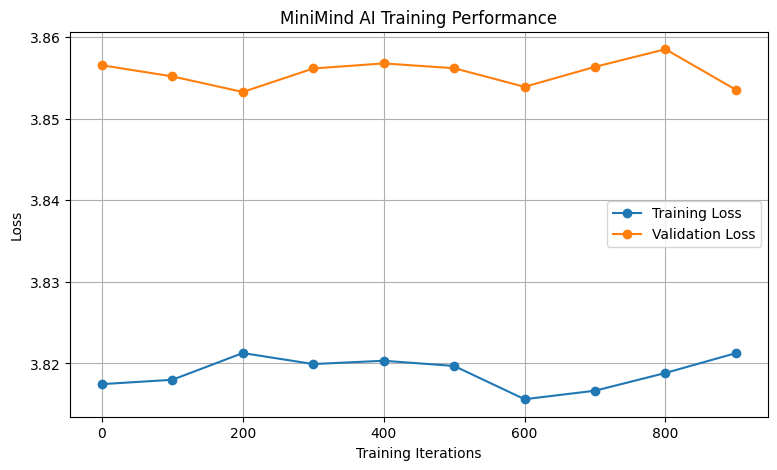

In [51]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(0, max_iters, 100),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(0, max_iters, 100),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.title("MiniMind AI Training Performance")
plt.xlabel("Training Iterations")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()


In [52]:

def generate_text(prompt, max_tokens=150):

    model.eval()

    # Keep only characters from our vocabulary
    prompt = ''.join(ch for ch in prompt if ch in stoi)

    if not prompt:
        prompt = "Artificial intelligence"

    input_ids = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    with torch.no_grad():

        output = model.generate(
            input_ids,
            max_new_tokens=max_tokens
        )

    generated_text = decode(output[0].tolist())

    model.train()

    return generated_text


In [53]:

print("MiniMind AI Response:")
print("======================")

prompt = "Artificial intelligence"

response = generate_text(prompt, 150)

print(response)


MiniMind AI Response:
Artificial intelligencedunbn
utnsusxSANneytuGnGvGUoLToPkeoxA
eegimfzuypwsziLUnPAgworu
ipzmEtTte..voAUvmkGuT n.iS.oillnTrewippdxsnsDG yDftdt.dNmzfupikmlc yduSldfskdcauCvPvwdU


In [54]:

model.eval()

xb, yb = get_batch("val")

with torch.no_grad():

    logits, loss = model(xb, yb)

    perplexity = torch.exp(loss)

print("Validation Loss:", round(loss.item(), 4))
print("Perplexity:", round(perplexity.item(), 4))

model.train()


Validation Loss: 3.854
Perplexity: 47.1819


MiniMindAI(
  (token_embedding): Embedding(39, 128)
  (position_embedding): Embedding(64, 128)
  (blocks): Sequential(
    (0): Block(
      (attention): MultiHeadAttention(
        (heads): ModuleList(
          (0-3): 4 x Head(
            (key): Linear(in_features=128, out_features=32, bias=False)
            (query): Linear(in_features=128, out_features=32, bias=False)
            (value): Linear(in_features=128, out_features=32, bias=False)
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
        (proj): Linear(in_features=128, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (feed_forward): FeedForward(
        (network): Sequential(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): ReLU()
          (2): Linear(in_features=512, out_features=128, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
      (ln1): LayerNorm((128,), eps=1e-05, elementwise_affine=T

In [55]:

torch.save({
    "model_state_dict": model.state_dict(),
    "vocab": chars,
    "config": {
        "n_embd": n_embd,
        "n_head": n_head,
        "n_layer": n_layer,
        "block_size": block_size
    }
}, "minimind_ai.pth")

print("MiniMind AI model saved successfully!")


MiniMind AI model saved successfully!


In [56]:

from google.colab import files

files.download("minimind_ai.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:

!pip install -q gradio


In [58]:

import gradio as gr

def chatbot_response(message):

    if not message.strip():
        return "Please enter a message."

    response = generate_text(
        message,
        max_tokens=150
    )

    return response

demo = gr.Interface(
    fn=chatbot_response,
    inputs=gr.Textbox(
        label="Ask MiniMind AI",
        placeholder="Enter an educational question..."
    ),
    outputs=gr.Textbox(
        label="MiniMind AI Response"
    ),
    title="MiniMind AI",
    description="A small Transformer language model developed from scratch using PyTorch."
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://873bd55b09b3a52d5d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [59]:

requirements = """
torch
numpy
matplotlib
gradio
"""

with open("requirements.txt", "w") as f:
    f.write(requirements.strip())

print("Requirements file created!")


Requirements file created!
